# Exploración: ¿qué del comportamiento del cliente es real?

**Reto 3 · Comportamiento de compra de los clientes.** Este notebook es la fase de *comprensión de los datos* de CRISP-DM.
Responde la pregunta que define el proyecto: **¿se puede segmentar a los clientes por sus hábitos o solo por su valor?**

Usa las salidas del pipeline (`kedro run`), así que todas las cifras son reproducibles. Prueba central: comparar al
**mismo cliente** en dos periodos (ene–feb vs. mar–abr 2018). Si un rasgo describe al cliente, quien lo muestra en el
primer periodo debe mostrarlo también en el segundo.

In [1]:
import logging
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from kedro.framework.session import KedroSession
from kedro.framework.startup import bootstrap_project
from scipy import stats

from valor_clientes import estilo
from valor_clientes.clientes import resumir_clientes

logging.disable(logging.INFO)  # sin los logs de Kedro en el notebook
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
bootstrap_project(RAIZ)
with KedroSession.create(project_path=RAIZ) as session:
    catalogo = session.load_context().catalog

ventas = catalogo.load("ventas_primarias")
calidad = catalogo.load("reporte_calidad_datos")
estabilidad = catalogo.load("estabilidad_clientes")
segmentacion = catalogo.load("segmentacion_kmeans")
regional = catalogo.load("perfil_regional")
temporal = catalogo.load("perfil_temporal")
ventanas = catalogo.load("params:ventanas")
%matplotlib inline
REPORTES = RAIZ / "data" / "08_reporting"
plt.rcParams.update({"figure.facecolor": estilo.COLOR_FONDO, "figure.dpi": 110})
print(
    f"{len(ventas):,} líneas de venta · {ventas['cliente_id'].nunique():,} clientes · "
    f"{ventas['producto_id'].nunique()} productos · {ventas['ciudad'].nunique()} ciudades"
)

[11/10/26 16:00:03] WARNING  /Users/milton/Github/MLB/ProyectoFinal/valor-clientes/.venv/lib/python ]8;id=8353326;file:///opt/homebrew/Cellar/python@3.12/3.12.13_4/Frameworks/Python.framework/Versions/3.12/lib/python3.12/warnings.py\warnings.py]8;;\:]8;id=8353327;file:///opt/homebrew/Cellar/python@3.12/3.12.13_4/Frameworks/Python.framework/Versions/3.12/lib/python3.12/warnings.py#112\112]8;;\
                             3.12/site-packages/kedro/config/omegaconf_config.py:637: UserWarning:                 
                             register_new_resolver() is deprecated and will be removed in a future                 
                             release.                                                                              
                             Use register_resolver() instead.                                                      
                             See https://github.com/hydra-ecosystem/omegaconf/issues/426 for                       
                             migration instructions.                                                               
                                                                                                                   
                               OmegaConf.register_new_resolver(                                                    
                                                                                                                   

                    WARNING  /Users/milton/Github/MLB/ProyectoFinal/valor-clientes/.venv/lib/python ]8;id=8353332;file:///opt/homebrew/Cellar/python@3.12/3.12.13_4/Frameworks/Python.framework/Versions/3.12/lib/python3.12/warnings.py\warnings.py]8;;\:]8;id=8353333;file:///opt/homebrew/Cellar/python@3.12/3.12.13_4/Frameworks/Python.framework/Versions/3.12/lib/python3.12/warnings.py#112\112]8;;\
                             3.12/site-packages/kedro/config/omegaconf_config.py:644: UserWarning:                 
                             register_new_resolver() is deprecated and will be removed in a future                 
                             release.                                                                              
                             Use register_resolver() instead.                                                      
                             See https://github.com/hydra-ecosystem/omegaconf/issues/426 for                       
                             migration instructions.                                                               
                                                                                                                   
                               OmegaConf.register_new_resolver(                                                    
                                                                                                                   

6,690,599 líneas de venta · 98,759 clientes · 452 productos · 96 ciudades


## 1. Los datos y su calidad

Siete tablas (ventas, productos, categorías, clientes, ciudades, países y empleados). El dataset **no está curado**.

In [2]:
h = calidad["hallazgos"]
resumen_calidad = pd.DataFrame(
    [
        (
            "Ventas (filas)",
            f"{calidad['filas']['ventas']:,}",
            "Una fila = un producto comprado; TransactionNumber es único por fila, no hay canastas",
        ),
        (
            "TotalPrice en cero",
            f"{h['pct_total_price_en_cero']}%",
            "Se recalcula: ingreso = precio × cantidad × (1 − descuento)",
        ),
        (
            "Ventas sin fecha",
            f"{calidad['faltantes']['ventas']['SalesDate']:,} ({h['pct_ventas_sin_fecha']}%)",
            "Se eliminan: no se pueden asignar a un periodo",
        ),
        (
            "Duplicados en ventas",
            str(calidad["duplicados"]["ventas_sales_id"]),
            "Ninguno por SalesID ni por fila completa",
        ),
        (
            "Clientes con el mismo nombre",
            f"{calidad['duplicados']['clientes_mismo_nombre']:,}",
            "Todos con dirección distinta: personas distintas, se conservan",
        ),
        (
            "Inicial del segundo nombre vacía",
            str(calidad["faltantes"]["clientes"]["MiddleInitial"]),
            "No se usa en el análisis",
        ),
        (
            "Países con clientes",
            ", ".join(
                f"{p['CountryName']} (código {p['CountryCode']})"
                for p in h["paises_con_clientes"]
            ),
            "Un solo país y con código mal asignado: no hay análisis entre países",
        ),
        (
            "Rango de fechas",
            f"{h['fecha_minima'][:10]} a {h['fecha_maxima'][:10]}",
            "Mayo incompleto (9 días): no se usa como objetivo",
        ),
        (
            "Rango de precio",
            f"{h['rango_precio'][0]} a {h['rango_precio'][1]}",
            "Repartido parejo de 0 a 100: el precio bajo no es error de captura",
        ),
        ("Integridad referencial", "0 huérfanos", "Todas las llaves foráneas existen"),
    ],
    columns=["Aspecto", "Valor", "Decisión"],
)
resumen_calidad.style.hide(axis="index")

Aspecto,Valor,Decisión
Ventas (filas),"6,758,125","Una fila = un producto comprado; TransactionNumber es único por fila, no hay canastas"
TotalPrice en cero,100.0%,Se recalcula: ingreso = precio × cantidad × (1 − descuento)
Ventas sin fecha,"67,526 (1.0%)",Se eliminan: no se pueden asignar a un periodo
Duplicados en ventas,0,Ninguno por SalesID ni por fila completa
Clientes con el mismo nombre,"4,897","Todos con dirección distinta: personas distintas, se conservan"
Inicial del segundo nombre vacía,977,No se usa en el análisis
Países con clientes,United States (código AR),Un solo país y con código mal asignado: no hay análisis entre países
Rango de fechas,2018-01-01 a 2018-05-09,Mayo incompleto (9 días): no se usa como objetivo
Rango de precio,0.0449 a 99.8755,Repartido parejo de 0 a 100: el precio bajo no es error de captura
Integridad referencial,0 huérfanos,Todas las llaves foráneas existen


## 2. Distribuciones: señales de un dataset sintético

Antes de segmentar conviene ver la forma de las variables. Tres patrones llaman la atención:

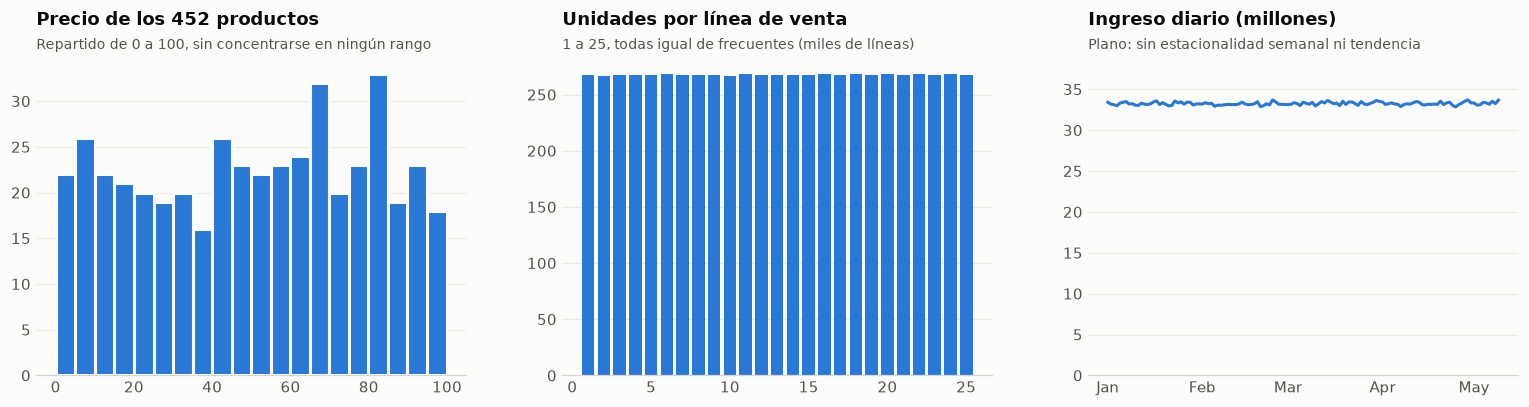

In [3]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8))
productos = ventas.drop_duplicates("producto_id")
ejes[0].hist(
    productos["precio"],
    bins=20,
    color=estilo.COLOR_SENAL,
    edgecolor=estilo.COLOR_FONDO,
    linewidth=2,
)
estilo.titulo(
    ejes[0],
    "Precio de los 452 productos",
    "Repartido de 0 a 100, sin concentrarse en ningún rango",
)
cantidad = ventas["cantidad"].value_counts().sort_index()
ejes[1].bar(cantidad.index, cantidad / 1e3, color=estilo.COLOR_SENAL, width=0.8)
estilo.titulo(
    ejes[1],
    "Unidades por línea de venta",
    "1 a 25, todas igual de frecuentes (miles de líneas)",
)
diario = ventas.groupby(ventas["fecha"].dt.normalize())["ingreso"].sum() / 1e6
ejes[2].plot(diario.index, diario, color=estilo.COLOR_SENAL, linewidth=2)
ejes[2].set_ylim(0, diario.max() * 1.15)
ejes[2].xaxis.set_major_locator(mdates.MonthLocator())
ejes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
estilo.titulo(
    ejes[2],
    "Ingreso diario (millones)",
    "Plano: sin estacionalidad semanal ni tendencia",
)
for ax in ejes:
    estilo.estilo_ejes(ax)
fig.tight_layout()

In [4]:
print(
    f"Participación por hora: {temporal['pct_ventas_por_hora_min_max'][0]}% a {temporal['pct_ventas_por_hora_min_max'][1]}% (24 horas parejas, también de madrugada)"
)
print(
    f"Variación del ingreso diario: {temporal['ingreso_diario_cv_pct']}% · mejor día de la semana / peor: {temporal['ingreso_por_dia_semana_max_sobre_min']}"
)
print(
    "Unidades promedio por nivel de descuento:",
    temporal["unidades_promedio_por_descuento"],
)

Participación por hora: 4.154% a 4.179% (24 horas parejas, también de madrugada)
Variación del ingreso diario: 0.554% · mejor día de la semana / peor: 1.0025
Unidades promedio por nivel de descuento: {'0.0': 13.002, '0.1': 13.023, '0.2': 13.0}


**Lectura:** ventas iguales a toda hora, todos los días, y el descuento no cambia cuánto se compra (13.0 unidades con o sin él).
No hay patrones temporales que una estrategia de comunicación pueda aprovechar (horarios, días, promociones).

## 3. ¿Cada cuánto compra un cliente? Indistinguible del azar

Si algunos clientes fueran más frecuentes que otros, la dispersión del número de compras sería mayor que la de un
conteo puramente aleatorio (Poisson, donde varianza = media).

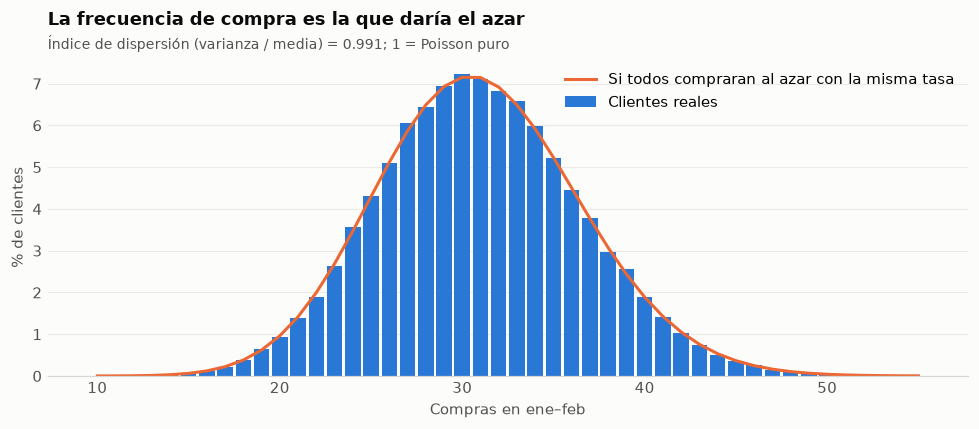

In [5]:
a = resumir_clientes(ventas, ventanas["inicio_observacion"], ventanas["corte"])
n = a["n_compras"]
k = np.arange(n.min(), n.max() + 1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(
    k,
    n.value_counts().reindex(k, fill_value=0) / len(n) * 100,
    color=estilo.COLOR_SENAL,
    width=0.85,
    label="Clientes reales",
)
ax.plot(
    k,
    stats.poisson.pmf(k, n.mean()) * 100,
    color=estilo.COLOR_ACENTO,
    linewidth=2,
    label="Si todos compraran al azar con la misma tasa",
)
ax.legend(frameon=False, loc="upper right")
ax.set_xlabel("Compras en ene–feb", color=estilo.COLOR_TEXTO_SECUNDARIO)
ax.set_ylabel("% de clientes", color=estilo.COLOR_TEXTO_SECUNDARIO)
estilo.estilo_ejes(ax)
estilo.titulo(
    ax,
    "La frecuencia de compra es la que daría el azar",
    f"Índice de dispersión (varianza / media) = {estabilidad['indice_dispersion_frecuencia']}; 1 = Poisson puro",
)
fig.tight_layout()

**Lectura:** la distribución real coincide con la de Poisson. Que un cliente compre 25 o 40 veces en dos meses no dice
nada de él: es la variación que tendría cualquier cliente. Un programa de lealtad basado en "clientes frecuentes"
estaría premiando suerte.

## 4. Qué se repite en el mismo cliente entre periodos

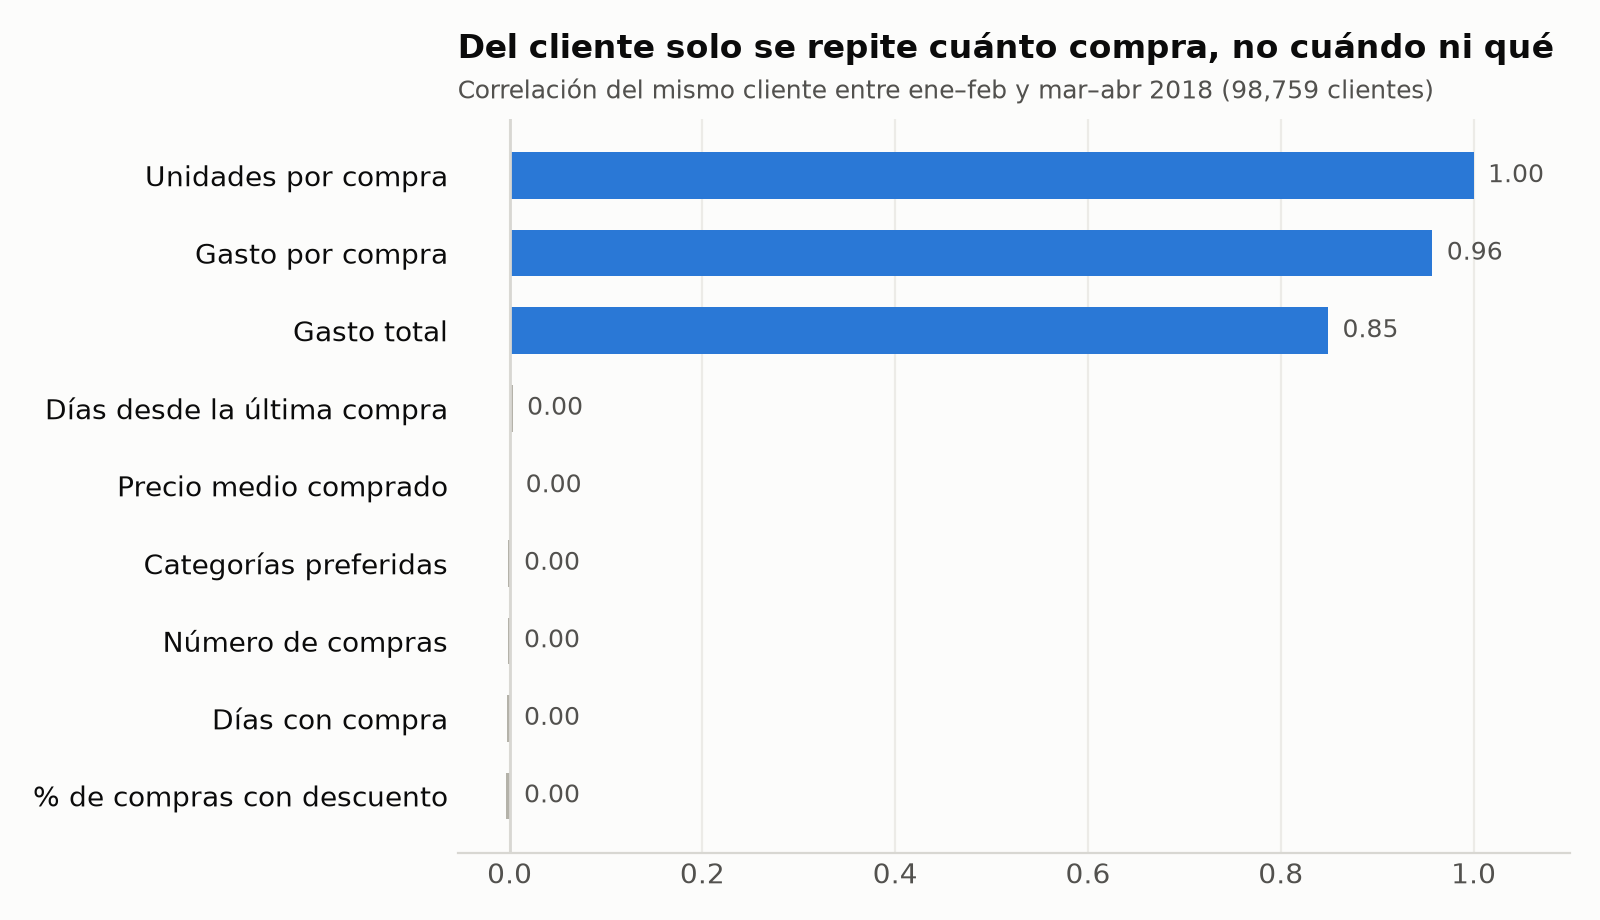

In [6]:
display(Image(REPORTES / "estabilidad_clientes.png", width=760))

In [7]:
pd.Series(
    estabilidad["correlacion_entre_periodos"], name="correlación ene–feb vs. mar–abr"
).round(3).to_frame()

,correlación ene–feb vs. mar–abr
unidades_por_compra,1.000
ticket_medio,0.957
ingreso,0.849
recencia_dias,0.003
precio_medio,0.002
mezcla_categorias,-0.001
n_compras,-0.002
dias_activos,-0.003
pct_descuento,-0.004


**Lectura:** solo tres rasgos son estables y los tres son de **valor**: cuántas unidades lleva por compra (correlación 1.00:
el 99.98% de los clientes compra **siempre la misma cantidad**), su gasto por compra y su gasto total.
Frecuencia, recencia, días activos, categorías preferidas, precio de lo que compra y uso de descuentos tienen correlación ~0:
cambian de un periodo a otro como si se sortearan.

## 5. Por qué no aplicamos una segmentación clásica

Probamos K-Means con 3, 4 y 5 segmentos sobre tres conjuntos de variables, **por separado en cada periodo**, y medimos
cuánto coinciden los segmentos del mismo cliente con el índice de Rand ajustado (ARI: 1 = mismos segmentos, 0 = azar).
La silueta mide qué tan separados quedan los grupos (cerca de 0 = grupos que no se distinguen).

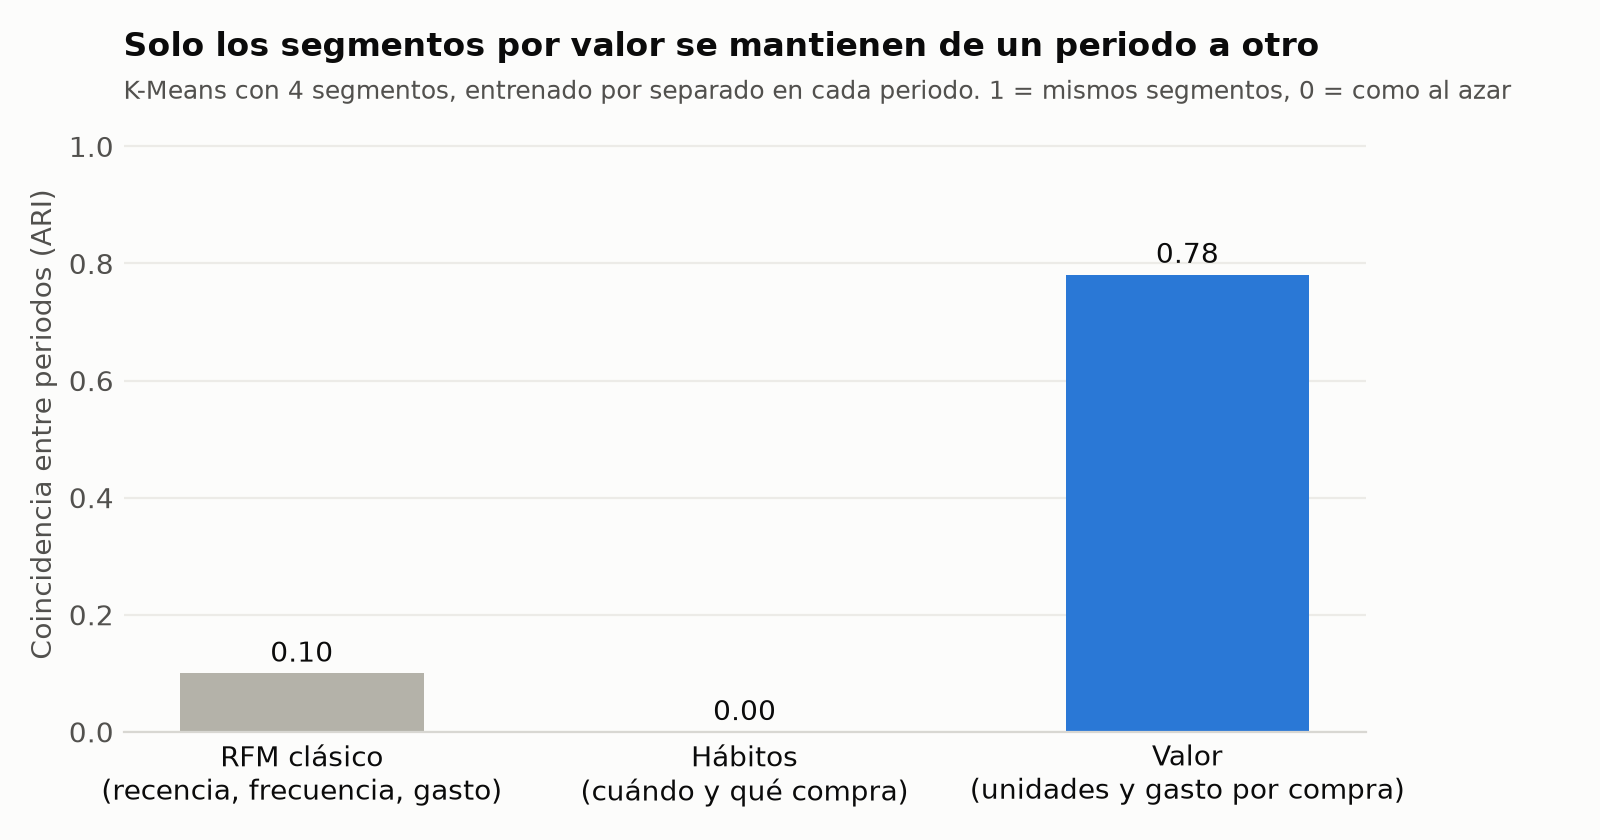

In [8]:
display(Image(REPORTES / "segmentacion_kmeans.png", width=760))

In [9]:
filas = [
    {"conjunto": nombre, "k": k, **valores}
    for nombre, datos in segmentacion.items()
    for k, valores in datos["por_k"].items()
]
pd.DataFrame(filas).pivot(
    index="conjunto", columns="k", values=["ari_entre_periodos", "silueta_periodo_a"]
).round(3)

ari_entre_periodos               silueta_periodo_a              
k                            3      4      5                 3      4      5
conjunto                                                                    
habitos                  0.000 -0.000  0.000             0.056  0.065  0.057
rfm_clasico              0.084  0.100  0.126             0.312  0.287  0.276
valor                    0.826  0.781  0.748             0.564  0.531  0.503

**Lectura:**

- **Hábitos** (cuándo y qué compra): ARI = 0.00 y silueta ≈ 0.06. Los grupos ni se separan ni se repiten: no existen.
- **RFM clásico**: ARI ≈ 0.10. Aunque incluye el gasto (que sí es estable), la recencia y la frecuencia —que son azar— dominan
  la segmentación y la vuelven inestable. Una campaña dirigida a "clientes en riesgo" o "frecuentes" apuntaría a personas distintas cada mes.
- **Valor** (unidades y gasto por compra): ARI ≈ 0.78 y silueta ≈ 0.53. Es la única segmentación que describe algo real.

**Conclusión:** una segmentación clásica produciría segmentos que se ven bien en una diapositiva pero no se sostienen en el
tiempo. Por eso el proyecto se enfoca en el **valor futuro del cliente**, que sí es estable y por lo tanto predecible.

## 6. Diferencias por región

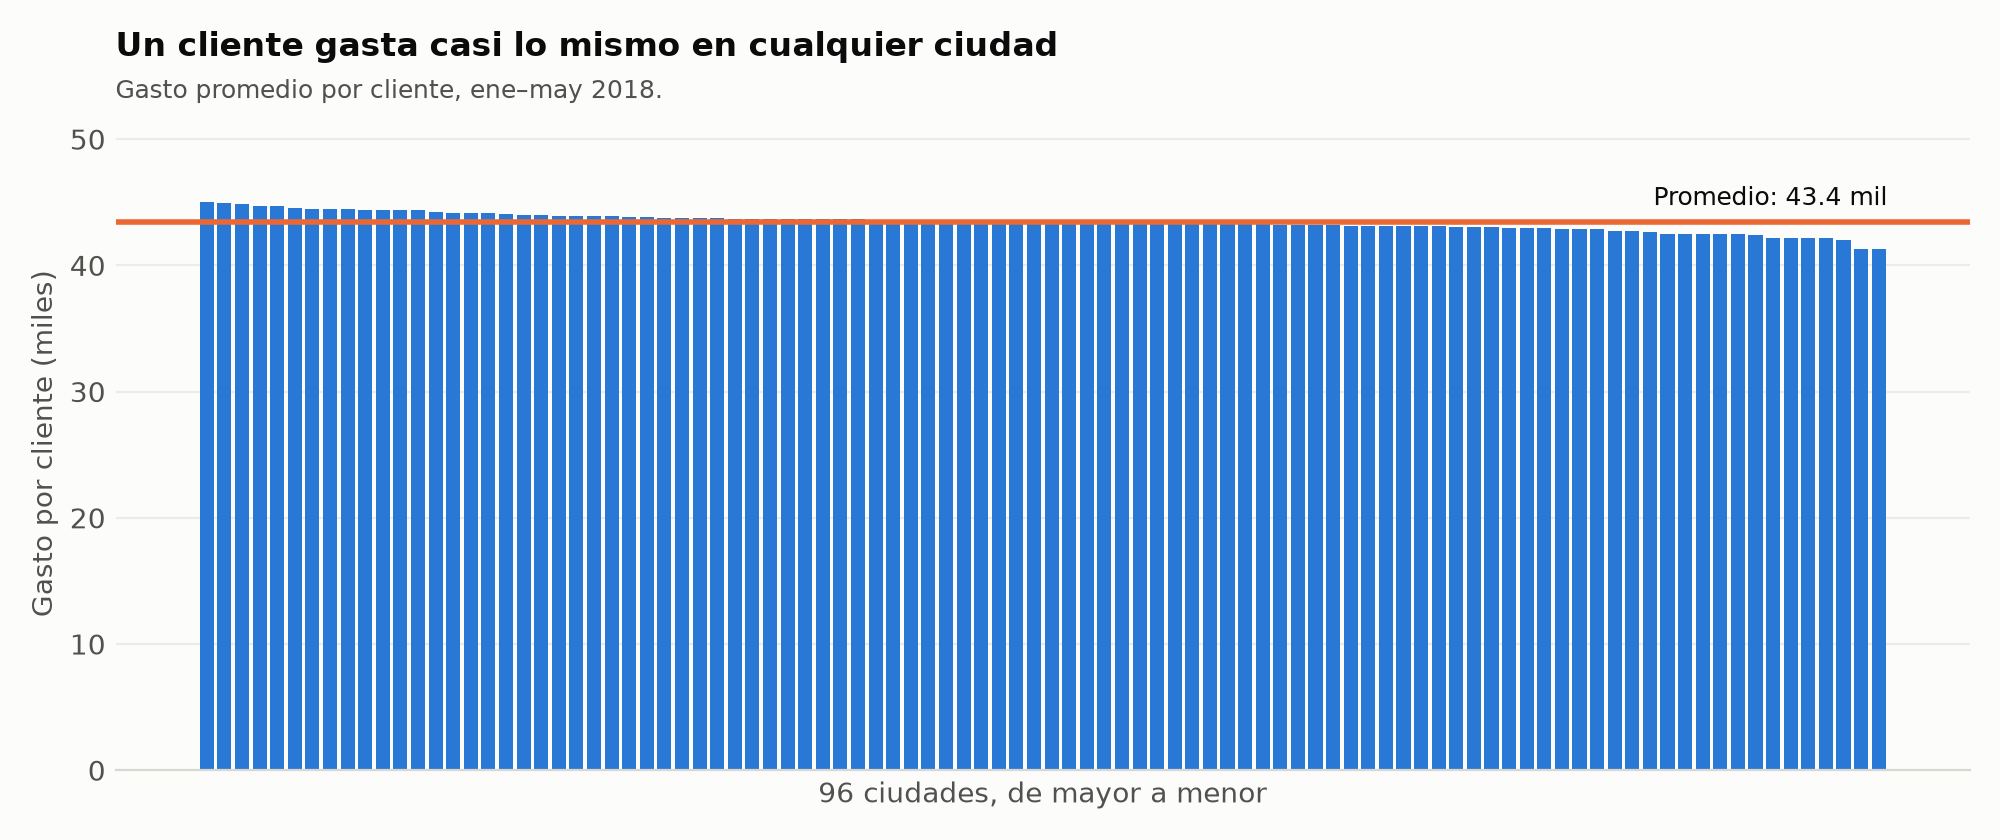

In [10]:
display(Image(REPORTES / "perfil_regional.png", width=900))

In [11]:
print(
    f"Ciudades: {regional['ciudades']} (un solo país) · clientes por ciudad: {regional['clientes_por_ciudad_min_max']}"
)
print(
    f"Gasto por cliente: variación entre ciudades {regional['gasto_por_cliente_cv_pct']}%, mejor/peor = {regional['gasto_por_cliente_max_sobre_min']}"
)
print(
    f"Prueba F de igualdad de medias: F = {regional['prueba_f_gasto_por_ciudad']['f']}, p = {regional['prueba_f_gasto_por_ciudad']['p_valor']}"
)
print(
    f"Mayor desviación de una categoría en una ciudad respecto a la mezcla nacional: {regional['max_desviacion_categoria_pp']} puntos porcentuales"
)

Ciudades: 96 (un solo país) · clientes por ciudad: [964, 1104]
Gasto por cliente: variación entre ciudades 1.68%, mejor/peor = 1.09
Prueba F de igualdad de medias: F = 0.864, p = 0.8251
Mayor desviación de una categoría en una ciudad respecto a la mezcla nacional: 0.37 puntos porcentuales


**Lectura:** con p = 0.83 no hay evidencia de que el gasto por cliente difiera entre ciudades, y ninguna ciudad se desvía
más de 0.4 puntos de la mezcla nacional de categorías. Una campaña regional no tendría a qué adaptarse.

## 7. Qué implica para la pregunta de negocio

| Lo que se esperaría en un reto de comportamiento de clientes | Lo que muestran los datos | Implicación |
|---|---|---|
| Segmentos por frecuencia/recencia (RFM) | Frecuencia = azar (Poisson); segmentos RFM no se repiten (ARI 0.10) | No usar RFM para dirigir campañas |
| Preferencias por categoría para venta cruzada | Mezcla de categorías no persiste (corr. ~0) | No personalizar por categoría |
| Diferencias regionales | 96 ciudades iguales (p = 0.83) | Campaña nacional, no regional |
| Horarios y días pico | 24 h y 7 días parejos | Sin ventanas horarias que aprovechar |
| Sensibilidad al descuento | Mismas unidades con o sin descuento | El descuento no mueve volumen |
| **Valor del cliente** | **Estable (corr. 0.85–1.00) y separable (ARI 0.78)** | **Priorizar clientes por valor futuro** |

**Pregunta:** *¿A qué clientes debe dirigir Marketing su próxima campaña, según cuánto van a comprar en los próximos meses?*

La tabla de entrada del modelo (`tabla_modelo`) ya está construida: variables de ene–feb y objetivo `ingreso_objetivo` de mar–abr.

In [12]:
tabla = catalogo.load("tabla_modelo")
print(tabla.shape)
tabla.head()

(98759, 24)


,cliente_id,n_compras,dias_activos,recencia_dias,unidades_total,unidades_por_compra,ingreso,ticket_medio,precio_medio,pct_descuento,...,cat_grain,cat_meat,cat_poultry,cat_produce,cat_seafood,cat_shell_fish,cat_snails,ciudad,ingreso_objetivo,compras_objetivo
0,1,34,25,0,34,1.0,1859.79351,54.699809,55.906485,0.117647,...,0.117647,0.088235,0.147059,0.147059,0.088235,0.058824,0.058824,Oklahoma,1248.24787,27
1,2,40,25,2,40,1.0,2189.35271,54.733818,56.065967,0.200000,...,0.150000,0.075000,0.050000,0.050000,0.125000,0.050000,0.100000,Pittsburgh,1037.03863,20
2,3,25,18,0,25,1.0,1212.40141,48.496056,49.418400,0.160000,...,0.080000,0.120000,0.120000,0.040000,0.080000,0.120000,0.040000,Houston,1728.57259,36
3,4,35,26,0,35,1.0,1482.33998,42.352571,43.551126,0.114286,...,0.057143,0.171429,0.085714,0.057143,0.057143,0.171429,0.057143,Cleveland,1382.40223,29
4,5,27,22,0,27,1.0,1285.82040,47.622978,50.943852,0.296296,...,0.037037,0.074074,0.037037,0.037037,0.074074,0.074074,0.000000,Buffalo,1207.20821,27
